Figure 3 top points from ML dataset: 561
LSV extraction errors: 0
Group counts:
group
Others    503
Co         29
Fe         29

Geometry-area corrected samples:


,sample,LSV_geometry_area_cm2,target_current_A_raw,eta10_mV_vs_RHE,eta10_mV_vs_RHE_full_lsv,separation_coefficient
6,Ag-Ce,2.0,-0.02,461.673080,461.673080,6.1
116,Co-V,2.0,-0.02,116.568181,116.568181,9.3
367,Mo-Mg,2.0,-0.02,572.910000,705.359886,6.0



Largest plotted eta10 values:


,sample,eta10_mV_vs_RHE,eta10_mV_vs_RHE_full_lsv,eta10_common_window_is_capped,separation_coefficient
367,Mo-Mg,572.910000,705.359886,True,6.000000
446,V-Al,571.423782,571.423782,True,2.696930
47,Cd-Mg,571.423186,571.423186,True,4.356956
129,Cr-Eu,571.422947,571.422947,True,3.989103
194,Eu-Mo,571.421993,571.421993,True,5.409435
123,Cr-Ca,571.420801,571.420801,True,3.705667
122,Cr-Ba,571.419013,571.419013,True,2.322440
464,V-Pb,571.417225,571.417225,True,3.420436
279,In-Mg,571.417225,571.417225,True,4.001837
445,V-Ag,571.416629,571.416629,True,2.982056


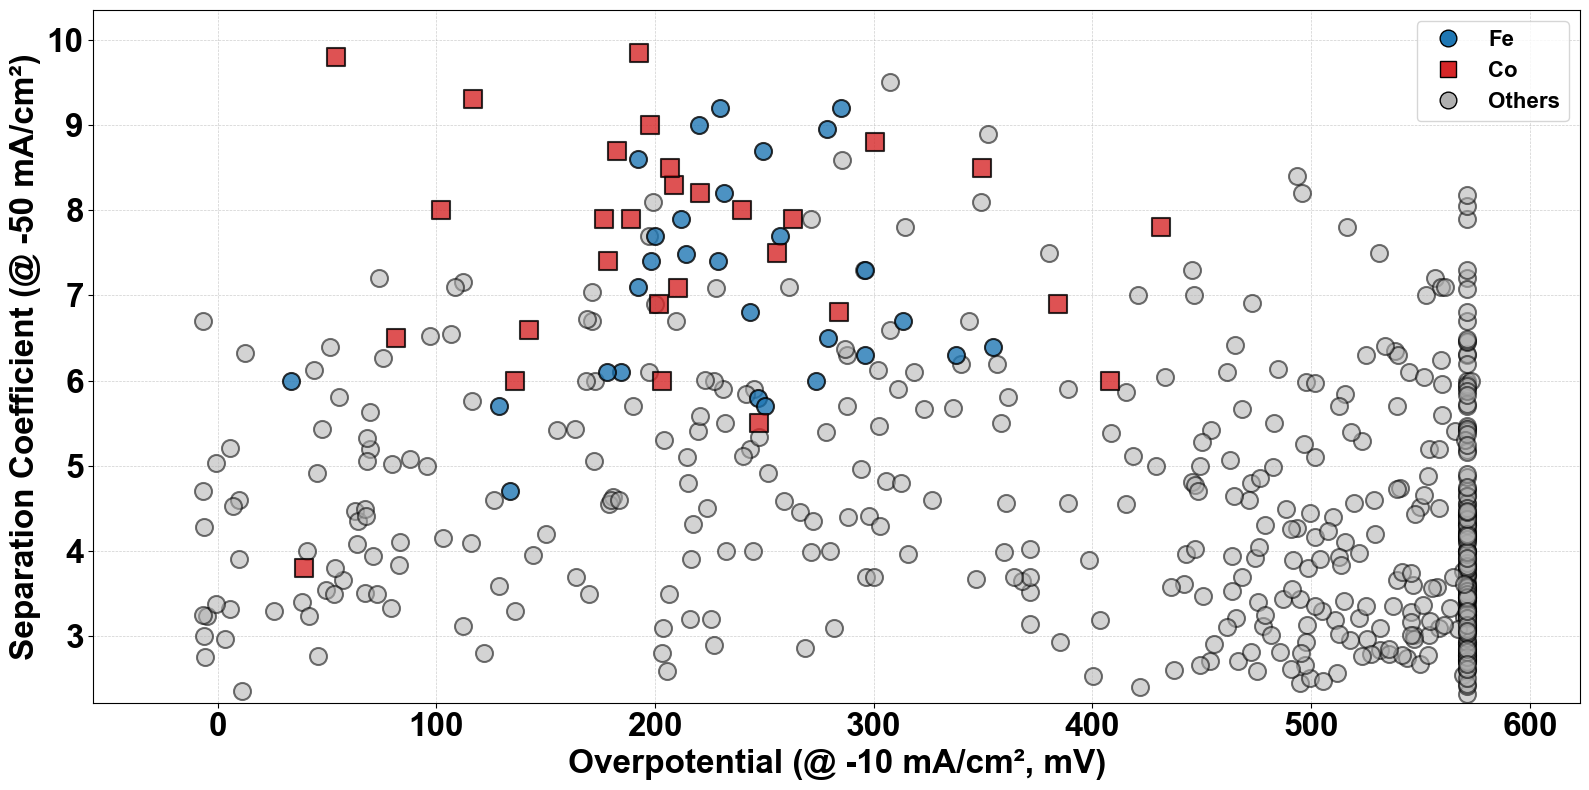

Saved data: C:\Users\yibinjiang\Documents\GitHub\HD_separation\0-Figures\Figure3\data\figure3_top_from_ml_dataset.csv
Saved figure: C:\Users\yibinjiang\Documents\GitHub\HD_separation\0-Figures\Figure3\outputs\before_BO_Fe_Co_Others.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties

# =========================
# Locate repository and data
# =========================

def find_repo_root(start=None):
    path = Path.cwd() if start is None else Path(start)
    for candidate in [path, *path.parents]:
        if (candidate / "hd_separation_ml").exists() and (candidate / "0-Figures").exists():
            return candidate
    raise FileNotFoundError("Could not locate HD_separation repo root from current working directory.")

repo_root = find_repo_root()
figure3_dir = repo_root / "0-Figures" / "Figure3"
ml_matrix_path = repo_root / "hd_separation_ml" / "outputs" / "final_model_8features_561_seed17_rs_from_eis" / "feature_matrix_8features.csv"
lsv_dir = repo_root / "hd_separation_ml" / "data_extraction" / "all_data" / "LSV"
geometry_metadata_path = lsv_dir / "lsv_geometry_area_metadata.csv"

output_data_path = figure3_dir / "data" / "figure3_top_from_ml_dataset.csv"
output_figure_path = figure3_dir / "outputs" / "before_BO_Fe_Co_Others.png"

figure3_dir.joinpath("data").mkdir(parents=True, exist_ok=True)
figure3_dir.joinpath("outputs").mkdir(parents=True, exist_ok=True)

# =========================
# Constants
# =========================

SHE_OFFSET_V = 0.098
PH14_OFFSET_V = 0.0592 * 14
RHE_OFFSET_V = SHE_OFFSET_V + PH14_OFFSET_V
STANDARD_TARGET_A_PER_CM2 = -0.010
STANDARD_GEOMETRY_AREA_CM2 = 1.0
COMMON_LSV_E_MIN_V = -1.50

# =========================
# Helpers
# =========================

def split_numeric_line(line):
    return [x for x in re.split(r"[,\s\t]+", line.strip()) if x]


def read_three_column_curve(path):
    rows = []
    for line in Path(path).read_text(errors="replace").splitlines():
        parts = split_numeric_line(line)
        if len(parts) < 3:
            continue
        try:
            rows.append([float(parts[0]), float(parts[1]), float(parts[2])])
        except ValueError:
            continue
    if not rows:
        raise ValueError(f"No numeric LSV rows parsed from {path}")
    return pd.DataFrame(rows, columns=["Potential_V_raw", "Current_A_raw", "Time_s"])


def potential_at_current_from_df(lsv, target_current_A):
    """Return the worst/most negative potential where the raw LSV crosses target current.

    Some LSV traces are non-monotonic and can hit the target current more than
    once. For conservative reporting, choose the most negative crossing, i.e.
    the largest overpotential. If the target is never crossed,
    use the point with the nearest current and mark it as outside range.
    """
    lsv = lsv.replace([np.inf, -np.inf], np.nan).dropna(subset=["Potential_V_raw", "Current_A_raw"])
    if len(lsv) == 0:
        raise ValueError("No finite current/potential rows")

    potentials = lsv["Potential_V_raw"].to_numpy(dtype=float)
    currents = lsv["Current_A_raw"].to_numpy(dtype=float)

    crossings = []
    for i in range(len(lsv) - 1):
        y0 = currents[i] - target_current_A
        y1 = currents[i + 1] - target_current_A
        if abs(y0) < 1e-12:
            crossings.append((float(potentials[i]), float(target_current_A)))
        if y0 * y1 < 0 or abs(y1) < 1e-12:
            frac = (target_current_A - currents[i]) / (currents[i + 1] - currents[i]) if currents[i + 1] != currents[i] else 0.0
            e_cross = potentials[i] + frac * (potentials[i + 1] - potentials[i])
            crossings.append((float(e_cross), float(target_current_A)))

    if crossings:
        e_cross, current_used = min(crossings, key=lambda item: item[0])
        return e_cross, True, current_used

    idx = int(np.nanargmin(np.abs(currents - target_current_A)))
    return float(potentials[idx]), False, float(currents[idx])


def load_geometry_area_map():
    if not geometry_metadata_path.exists():
        return {}
    meta = pd.read_csv(geometry_metadata_path)
    meta["catalyst"] = meta["catalyst"].astype(str)
    meta["geometry_area_cm2"] = pd.to_numeric(meta["geometry_area_cm2"], errors="coerce")
    meta = meta.dropna(subset=["catalyst", "geometry_area_cm2"])
    return dict(zip(meta["catalyst"], meta["geometry_area_cm2"]))


def assign_group(metal):
    if metal == "Fe":
        return "Fe"
    if metal == "Co":
        return "Co"
    return "Others"

# =========================
# Build Figure 3 top dataset from current ML-retained no-BO samples
# =========================

ml_data = pd.read_csv(ml_matrix_path)
ml_data = ml_data.loc[:, ~ml_data.columns.duplicated()].copy()
required_columns = {"sample", "element1", "element2", "separation_coefficient"}
missing_columns = required_columns - set(ml_data.columns)
if missing_columns:
    raise ValueError(f"ML matrix missing columns: {sorted(missing_columns)}")

geometry_area_map = load_geometry_area_map()
records = []
errors = []

for _, row in ml_data.iterrows():
    sample = str(row["sample"])
    lsv_path = lsv_dir / f"{sample}.txt"
    if not lsv_path.exists():
        errors.append({"sample": sample, "reason": "missing_LSV"})
        continue

    area_cm2 = float(geometry_area_map.get(sample, STANDARD_GEOMETRY_AREA_CM2))
    target_current_A = STANDARD_TARGET_A_PER_CM2 * area_cm2
    try:
        lsv_full = read_three_column_curve(lsv_path)
        e_full, full_inside, full_current_used = potential_at_current_from_df(lsv_full, target_current_A)
        lsv_common = lsv_full[lsv_full["Potential_V_raw"] >= COMMON_LSV_E_MIN_V].copy()
        e_common, common_inside, common_current_used = potential_at_current_from_df(lsv_common, target_current_A)
    except Exception as exc:
        errors.append({"sample": sample, "reason": f"parse_error: {exc}"})
        continue

    eta_full = -1000.0 * (e_full + RHE_OFFSET_V)
    eta_common = -1000.0 * (e_common + RHE_OFFSET_V)
    records.append({
        "sample": sample,
        "element1": row["element1"],
        "element2": row["element2"],
        "separation_coefficient": float(row["separation_coefficient"]),
        "LSV_geometry_area_cm2": area_cm2,
        "target_current_A_raw": target_current_A,
        "full_lsv_E_min_V": float(lsv_full["Potential_V_raw"].min()),
        "common_lsv_E_min_limit_V": COMMON_LSV_E_MIN_V,
        "E_raw_at_eta10_full_lsv_V": e_full,
        "eta10_mV_vs_RHE_full_lsv": eta_full,
        "target_inside_full_lsv_range": full_inside,
        "current_used_A_full_lsv": full_current_used,
        "E_raw_at_eta10_common_window_V": e_common,
        "eta10_mV_vs_RHE": eta_common,
        "target_inside_common_lsv_range": common_inside,
        "current_used_A_common_window": common_current_used,
        "eta10_common_window_is_capped": not common_inside,
        "group": assign_group(row["element1"]),
    })

filtered_data = pd.DataFrame(records).sort_values("sample").reset_index(drop=True)
filtered_data.to_csv(output_data_path, index=False, encoding="utf-8-sig")
if errors:
    pd.DataFrame(errors).to_csv(figure3_dir / "data" / "figure3_top_from_ml_dataset_errors.csv", index=False, encoding="utf-8-sig")

print(f"Figure 3 top points from ML dataset: {len(filtered_data)}")
print(f"LSV extraction errors: {len(errors)}")
print("Group counts:")
print(filtered_data["group"].value_counts().to_string())

geometry_corrected = filtered_data[filtered_data["LSV_geometry_area_cm2"].ne(1.0)]
if len(geometry_corrected):
    print("\nGeometry-area corrected samples:")
    display(geometry_corrected[["sample", "LSV_geometry_area_cm2", "target_current_A_raw", "eta10_mV_vs_RHE", "eta10_mV_vs_RHE_full_lsv", "separation_coefficient"]])

print("\nLargest plotted eta10 values:")
display(filtered_data.sort_values("eta10_mV_vs_RHE", ascending=False).head(10)[[
    "sample", "eta10_mV_vs_RHE", "eta10_mV_vs_RHE_full_lsv", "eta10_common_window_is_capped", "separation_coefficient"
]])

# =========================
# Plot using the legacy Figure 3 top style
# =========================

color_map = {
    "Fe": "#1f77b4",
    "Co": "#d62728",
    "Others": "#b0b0b0",
}

marker_map = {
    "Fe": "o",
    "Co": "s",
    "Others": "o",
}

plt.rcParams["font.family"] = "Arial"
fig, ax = plt.subplots(figsize=(16, 8))

for group in ["Others", "Fe", "Co"]:
    group_data = filtered_data[filtered_data["group"] == group]
    ax.scatter(
        group_data["eta10_mV_vs_RHE"],
        group_data["separation_coefficient"],
        color=color_map[group],
        alpha=0.8 if group != "Others" else 0.55,
        s=150,
        marker=marker_map[group],
        edgecolors="black",
        linewidth=1.5,
        zorder=3 if group != "Others" else 2,
    )

legend_handles = [
    Line2D(
        [0], [0],
        marker=marker_map[group],
        color="w",
        markerfacecolor=color_map[group],
        markeredgecolor="black",
        markersize=12,
        label=group,
    )
    for group in ["Fe", "Co", "Others"]
]
ax.legend(handles=legend_handles, loc="best", prop=FontProperties(weight="bold", size=16), frameon=True)

ax.set_ylabel("Separation Coefficient (@ -50 mA/cm²)", fontname="Arial", fontweight="bold", fontsize=24)
ax.set_xlabel("Overpotential (@ -10 mA/cm², mV)", fontname="Arial", fontweight="bold", fontsize=24)
ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.6)
ax.tick_params(axis="both", which="both", labelsize=24)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontname("Arial")
    label.set_fontweight("bold")

x = filtered_data["eta10_mV_vs_RHE"]
y = filtered_data["separation_coefficient"]
ax.set_xlim(x.min() - 50, x.max() + 50)
ax.set_ylim(y.min() - 0.1, y.max() + 0.5)

fig.tight_layout()
fig.savefig(output_figure_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"Saved data: {output_data_path}")
print(f"Saved figure: {output_figure_path}")
